# 01 — Observational effective dependency range

This notebook reproduces the observational context-utility results used in the paper.

It combines:

1. **Ghostbuster matched essays**, using the corrected 7-way source-matched corpus from `00c` and the exact historical scorer from corrected `00e`;
2. **RAID news and Wikipedia**, using the frozen matched RAID observational feature table;
3. **RAID model-specific \(U(256)\)** effects.

For each matched source \(s\) and generator \(g\),

\[
\Delta U_{g,s}(k)=U_{g,s}(k)-U_{\mathrm{human},s}(k).
\]

For Ghostbuster, all six machine generators must be available together with the matched human document. Their six utilities are averaged within source before subtracting the human value.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
PROJECT_ROOT = ROOT.parent

DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

KS = [32, 128, 256]
N_BOOT = 5000

In [2]:
GB_RAW_PATH = DATA / "raw" / "ghostbuster_essays.parquet"
GB_CONTEXT_PATH = RESULTS / "ghostbuster_essay_context.parquet"

raid_candidates = [
    DATA / "raid_pilot" / "raid_pilot_frozen_features.parquet",
    PROJECT_ROOT / "data" / "raid_pilot" / "raid_pilot_frozen_features.parquet",
    PROJECT_ROOT / "results" / "raid_pilot" / "raid_pilot_frozen_features.parquet",
]
RAID_PATH = next((p for p in raid_candidates if p.exists()), None)

assert GB_RAW_PATH.exists(), GB_RAW_PATH
assert GB_CONTEXT_PATH.exists(), GB_CONTEXT_PATH
assert RAID_PATH is not None, "Could not find raid_pilot_frozen_features.parquet"

print("Ghostbuster raw:", GB_RAW_PATH)
print("Ghostbuster context:", GB_CONTEXT_PATH)
print("RAID:", RAID_PATH)

Ghostbuster raw: ../data/raw/ghostbuster_essays.parquet
Ghostbuster context: ../results/ghostbuster_essay_context.parquet
RAID: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_pilot_frozen_features.parquet


## Ghostbuster: corrected source-matched context effects

The 7-way corpus contains one human essay plus six machine variants for each actual source ID. A source contributes only if all seven documents have non-null context utility.

In [3]:
gb_raw = pd.read_parquet(GB_RAW_PATH).copy()
gb_ctx = pd.read_parquet(GB_CONTEXT_PATH).copy()

gb = gb_raw.merge(
    gb_ctx[["row_id", "context_u_32", "context_u_128", "context_u_256"]],
    on="row_id",
    validate="one_to_one",
)

expected_generators = {
    "human", "gpt", "claude", "gpt_prompt1",
    "gpt_prompt2", "gpt_semantic", "gpt_writing",
}

assert len(gb) == 7000
assert gb["group_id"].nunique() == 1000
assert set(gb["generator"].unique()) == expected_generators
assert (gb.groupby("group_id")["generator"].nunique() == 7).all()

machine_generators = sorted(expected_generators - {"human"})

gb_source_rows = []

for k in KS:
    u_col = f"context_u_{k}"

    wide = gb.pivot(
        index="group_id",
        columns="generator",
        values=u_col,
    )

    complete = wide.dropna(subset=sorted(expected_generators))

    delta = (
        complete[machine_generators].mean(axis=1)
        - complete["human"]
    )

    for group_id, value in delta.items():
        gb_source_rows.append({
            "group_id": group_id,
            "k": k,
            "delta_u": float(value),
        })

    print(
        f"k={k}: complete groups={len(complete)}, "
        f"mean matched delta={delta.mean():.6f}"
    )

gb_source_long = pd.DataFrame(gb_source_rows)

display(gb_source_long.groupby("k")["delta_u"].describe())

k=32: complete groups=708, mean matched delta=0.316234
k=128: complete groups=708, mean matched delta=0.436648
k=256: complete groups=708, mean matched delta=0.477180


,count,mean,std,min,25%,50%,75%,max
k,,,,,,,,
32,708.0,0.316234,0.622969,-2.044501,-0.028629,0.372931,0.702300,2.086889
128,708.0,0.436648,0.785101,-2.577280,0.007087,0.490516,0.969031,2.731760
256,708.0,0.477180,0.825067,-2.792183,-0.036852,0.495806,1.025187,2.952485


Expected corrected Ghostbuster result:

\[
\Delta U(32)\approx 0.3162,\quad
\Delta U(128)\approx 0.4366,\quad
\Delta U(256)\approx 0.4772,
\]

with 708 complete 7-way matched groups.

## RAID matched context effects

In [4]:
raid = pd.read_parquet(RAID_PATH).copy()

required = {
    "source_id", "domain", "model",
    "context_u_32", "context_u_128", "context_u_256",
}
missing = required - set(raid.columns)
assert not missing, f"Missing RAID columns: {sorted(missing)}"

raid_human = (
    raid.loc[
        raid["model"] == "human",
        ["source_id", "domain"] + [f"context_u_{k}" for k in KS],
    ]
    .rename(columns={f"context_u_{k}": f"human_u_{k}" for k in KS})
)

raid_ai = raid.loc[
    raid["model"] != "human",
    ["source_id", "domain", "model"] + [f"context_u_{k}" for k in KS],
].copy()

raid_pairs = raid_ai.merge(
    raid_human,
    on=["source_id", "domain"],
    how="inner",
    validate="many_to_one",
)

for k in KS:
    raid_pairs[f"delta_u_{k}"] = (
        raid_pairs[f"context_u_{k}"] - raid_pairs[f"human_u_{k}"]
    )

raid_source = (
    raid_pairs.groupby(["domain", "source_id"])
    [[f"delta_u_{k}" for k in KS]]
    .mean()
    .reset_index()
)

print("paired sources:", raid_pairs["source_id"].nunique())
print("domains:", sorted(raid_pairs["domain"].unique()))
print("models:", sorted(raid_pairs["model"].unique()))

paired sources: 160
domains: ['news', 'wiki']
models: ['chatgpt', 'gpt2', 'gpt4', 'llama-chat', 'mistral', 'mpt']


In [5]:
def bootstrap_mean_ci(values, n_boot=N_BOOT, seed=42):
    x = pd.Series(values).dropna().to_numpy(float)
    assert len(x) > 0

    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)

    for b in range(n_boot):
        boot[b] = rng.choice(x, size=len(x), replace=True).mean()

    lo, hi = np.percentile(boot, [2.5, 97.5])

    return {
        "n": len(x),
        "mean_delta": float(x.mean()),
        "ci_low": float(lo),
        "ci_high": float(hi),
    }

## Cross-dataset result

In [6]:
summary_rows = []

for k in KS:
    g = gb_source_long[gb_source_long["k"] == k]
    summary_rows.append({
        "series": "Ghostbuster",
        "k": k,
        **bootstrap_mean_ci(g["delta_u"], seed=100 + k),
    })

for domain in sorted(raid_source["domain"].unique()):
    d = raid_source[raid_source["domain"] == domain]

    label = (
        "RAID news" if domain == "news"
        else "RAID wiki" if domain in {"wiki", "wikipedia"}
        else f"RAID {domain}"
    )

    for k in KS:
        summary_rows.append({
            "series": label,
            "k": k,
            **bootstrap_mean_ci(d[f"delta_u_{k}"], seed=1000 + k),
        })

summary = pd.DataFrame(summary_rows)

SUMMARY_PATH = RESULTS / "context_observational_summary.csv"
summary.to_csv(SUMMARY_PATH, index=False)

print("saved:", SUMMARY_PATH)
display(summary)

display(
    summary.pivot(
        index="series",
        columns="k",
        values="mean_delta",
    )
)

saved: ../results/context_observational_summary.csv


,series,k,n,mean_delta,ci_low,ci_high
0,Ghostbuster,32,708,0.316234,0.271175,0.362106
1,Ghostbuster,128,708,0.436648,0.380268,0.493114
2,Ghostbuster,256,708,0.477180,0.419073,0.538256
3,RAID news,32,80,0.559318,0.401315,0.711869
4,RAID news,128,80,0.902484,0.701557,1.098833
5,RAID news,256,80,0.908743,0.695698,1.114156
6,RAID wiki,32,80,0.360471,0.202954,0.515335
7,RAID wiki,128,80,0.686366,0.488203,0.881096
8,RAID wiki,256,80,0.700291,0.510023,0.887393


k,32,128,256
series,,,
Ghostbuster,0.316234,0.436648,0.477180
RAID news,0.559318,0.902484,0.908743
RAID wiki,0.360471,0.686366,0.700291


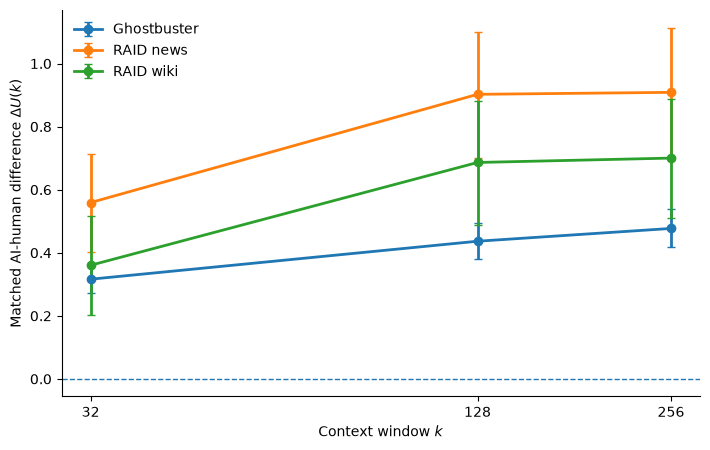

saved: ../figures/context_utility_cross_dataset.pdf
saved: ../figures/context_utility_cross_dataset.png


In [7]:
fig, ax = plt.subplots(figsize=(7.2, 4.6))

for name, s in summary.groupby("series"):
    s = s.sort_values("k")
    y = s["mean_delta"].to_numpy()
    err = np.vstack([
        y - s["ci_low"].to_numpy(),
        s["ci_high"].to_numpy() - y,
    ])

    ax.errorbar(
        s["k"], y, yerr=err,
        marker="o", linewidth=2, capsize=3,
        label=name,
    )

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xscale("log", base=2)
ax.set_xticks(KS)
ax.set_xticklabels(KS)
ax.set_xlabel("Context window $k$")
ax.set_ylabel(r"Matched AI-human difference $\Delta U(k)$")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

PDF_PATH = FIGURES / "context_utility_cross_dataset.pdf"
PNG_PATH = FIGURES / "context_utility_cross_dataset.png"

fig.savefig(PDF_PATH, bbox_inches="tight")
fig.savefig(PNG_PATH, dpi=300, bbox_inches="tight")
plt.show()

print("saved:", PDF_PATH)
print("saved:", PNG_PATH)

## Model-specific RAID \(U(256)\)

In [8]:
model_rows = []

for domain in sorted(raid_pairs["domain"].unique()):
    for model_name in sorted(raid_pairs["model"].unique()):
        d = raid_pairs[
            (raid_pairs["domain"] == domain)
            & (raid_pairs["model"] == model_name)
        ]

        if len(d) == 0:
            continue

        model_rows.append({
            "domain": domain,
            "model": model_name,
            "k": 256,
            **bootstrap_mean_ci(
                d["delta_u_256"],
                seed=2000 + sum(map(ord, domain + model_name)),
            ),
        })

model_effects = pd.DataFrame(model_rows)

MODEL_PATH = RESULTS / "raid_context_u256_by_model.csv"
model_effects.to_csv(MODEL_PATH, index=False)

print("saved:", MODEL_PATH)
display(model_effects)

saved: ../results/raid_context_u256_by_model.csv


,domain,model,k,n,mean_delta,ci_low,ci_high
0,news,chatgpt,256,80,0.242770,-0.009268,0.492835
1,news,gpt2,256,80,1.419977,1.151642,1.700356
2,news,gpt4,256,80,0.321345,0.058096,0.570736
3,news,llama-chat,256,80,0.278013,0.008902,0.555343
4,news,mistral,256,80,1.556295,1.240909,1.862521
5,news,mpt,256,80,1.634055,1.350994,1.917001
6,wiki,chatgpt,256,80,0.488695,0.233745,0.739725
7,wiki,gpt2,256,80,1.143528,0.879498,1.413097
8,wiki,gpt4,256,80,0.463654,0.212890,0.718133
9,wiki,llama-chat,256,80,0.307271,0.061015,0.561145


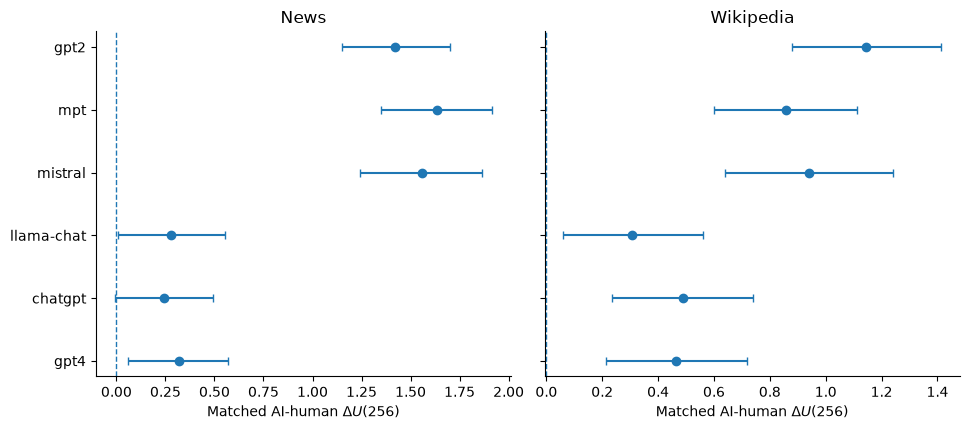

In [9]:
ORDER = ["gpt2", "mpt", "mistral", "llama-chat", "chatgpt", "gpt4"]

domains = [
    d for d in ["news", "wiki", "wikipedia"]
    if d in set(model_effects["domain"])
]
assert len(domains) == 2

fig, axes = plt.subplots(1, 2, figsize=(9.8, 4.4), sharey=True)

for ax, domain in zip(axes, domains):
    s = (
        model_effects[model_effects["domain"] == domain]
        .set_index("model")
        .reindex(ORDER)
        .dropna(subset=["mean_delta"])
        .reset_index()
    )

    y = np.arange(len(s))
    m = s["mean_delta"].to_numpy()

    err = np.vstack([
        m - s["ci_low"].to_numpy(),
        s["ci_high"].to_numpy() - m,
    ])

    ax.errorbar(m, y, xerr=err, fmt="o", capsize=3)
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(s["model"])
    ax.set_xlabel(r"Matched AI-human $\Delta U(256)$")
    ax.set_title("News" if domain == "news" else "Wikipedia")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].invert_yaxis()
fig.tight_layout()

PDF_PATH = FIGURES / "context_u256_by_model.pdf"
PNG_PATH = FIGURES / "context_u256_by_model.png"

fig.savefig(PDF_PATH, bbox_inches="tight")
fig.savefig(PNG_PATH, dpi=300, bbox_inches="tight")
plt.show()

## Regime-level diagnostic at k=256

In [10]:
regime_map = {
    "gpt2": "base",
    "mpt": "base",
    "mistral": "base",
    "llama-chat": "chat/aligned",
    "chatgpt": "chat/aligned",
    "gpt4": "chat/aligned",
}

tmp = raid_pairs[raid_pairs["model"].isin(regime_map)].copy()
tmp["regime"] = tmp["model"].map(regime_map)

regime_summary = (
    tmp.groupby(["domain", "regime"])["delta_u_256"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

display(regime_summary)

,domain,regime,count,mean,std
0,news,base,240,1.536776,1.323719
1,news,chat/aligned,240,0.280709,1.188478
2,wiki,base,240,0.980707,1.284845
3,wiki,chat/aligned,240,0.419874,1.163416
